In [1]:
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter

from das_tools import maps
from das_tools.utils import proj_path
from das_tools.readers import open_das
from das_tools.readers.onyx import _parse_onyx_start_time
from das_tools.processing import filter_dataset


In [2]:
# ============================================================
# User settings
# ============================================================

# Set to True only if your Python/Matplotlib setup has LaTeX available.
USE_TEX = False

# Consistent font sizes across all panels
TITLE_FONTSIZE = 18
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14
CBAR_LABEL_FONTSIZE = LABEL_FONTSIZE
CBAR_TICK_FONTSIZE = TICK_FONTSIZE
LEGEND_FONTSIZE = 12
PANEL_LABEL_FONTSIZE = 18

mpl.rcParams.update({
    "text.usetex": USE_TEX,
    "font.family": "serif",
    "font.size": LABEL_FONTSIZE,
    "axes.titlesize": TITLE_FONTSIZE,
    "axes.labelsize": LABEL_FONTSIZE,
    "xtick.labelsize": TICK_FONTSIZE,
    "ytick.labelsize": TICK_FONTSIZE,
    "legend.fontsize": LEGEND_FONTSIZE,
})

# ------------------------------------------------------------
# Panel (a): cable layout settings
# ------------------------------------------------------------
# Satellite background. data/satellite/ is not tracked: without the GeoTIFF (or
# without rasterio) the panel is drawn on a plain background in MAP_CRS.
GEOTIFF_PATH  = proj_path.data_dir("satellite", "20250503_050318_ssc4_u0001_visual_clip.tif")
MAP_CRS       = "EPSG:32604"   # UTM 4N, the GeoTIFF's CRS
MAP_FACECOLOR = "0.92"
KML_PATH      = proj_path.data_dir("CableRoute2025_onice_traced_smoothed.kml")

HALF_SIZE_KM_LAT = 0.6
HALF_SIZE_KM_LON = 0.6

TAP_TEST_CSV = proj_path.data_dir("tapTestInv_all.csv")  # hammer location of the panel (b) shot
N1_LATLON = np.asarray([71.339231,-156.663587])  # [lat, lon]
N2_LATLON = np.asarray([71.345249, -156.673896])  # [lat, lon]
N3_LATLON = np.asarray([71.349445, -156.658378])  # [lat, lon]
N4_LATLON = np.asarray([71.343134, -156.669881])  # [lat, lon]
N5_LATLON = np.asarray([71.347530, -156.674491])  # [lat, lon]
SWIFT_NC = proj_path.data_dir("SWIFT19_telemetry.nc")

# ------------------------------------------------------------
# Panel (c): flexural-gravity waterfall from the 5 Hz hourly file
# ------------------------------------------------------------
WATERFALL_FILE = proj_path.hourly_das_dir("das_20250505_230000_5Hz.h5")
WATERFALL_T0 = pd.Timestamp("2025-05-05 23:30:00")  # start of the plotted window (UTC)
WATERFALL_DURATION_S = 60.0
WATERFALL_DISTANCE_RANGE = (1200, 2060)  # y-axis range (m), same as panel (b)
WATERFALL_FMIN = 0.1
WATERFALL_FMAX = 1.0
WATERFALL_VMIN = -25
WATERFALL_VMAX = 25

# ------------------------------------------------------------
# Panel (b): hammer shot
# ------------------------------------------------------------
HAMMER_FILE = proj_path.hammer_das_dir("decimator_2025-04-24_00.27.00_UTC_000281.h5")
HAMMER_WINDOW_S = (36.5, 37.5)  # plotted window, s after the file start
HAMMER_DISTANCE_RANGE = (1200, 2060)
HAMMER_FMIN = 10
HAMMER_FMAX = 100.0
HAMMER_VMIN = -.5
HAMMER_VMAX = .5

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

OUT_PNG = FIGURE_DIR / "combined_cable_2waterfall_3col_annotated.png"
OUT_PDF = FIGURE_DIR / "combined_cable_2waterfall_3col_annotated.pdf"


# ============================================================
# Annotation settings (NEW)
# ============================================================

# ---- Panel (b): highlight box over a distance band, full time span ----
HIGHLIGHT_BOX_KM     = (1.70, 2.00)   # (lower, upper) channel distance in km
HIGHLIGHT_BOX_COLOR  = "green"
HIGHLIGHT_BOX_LW     = 3.0
HIGHLIGHT_BOX_LS     = "-"            # e.g. "-", "--"
HIGHLIGHT_BOX_ALPHA  = 1.0            # edge alpha
HIGHLIGHT_BOX_FACE   = "none"         # e.g. "blue" with FACE_ALPHA < 1 to shade
HIGHLIGHT_BOX_FACE_ALPHA = 0.10
HIGHLIGHT_BOX_X_INSET_FRAC = 0.004  # pull the box edges in from the spines so
                                    # the left/right sides are visible

# ---- Panel (c): wave-type labels with arrows ----
# Labels are written inside this distance band and stacked vertically
# (row 0 = top of the band), while being distributed horizontally in time.
WAVE_LABEL_BAND_KM  = (1.25, 1.40)
WAVE_LABEL_FONTSIZE = 16

# x positions are FRACTIONS of the panel's time axis (0 = left edge, 1 = right edge)
# so they are easy to nudge without knowing absolute timestamps.
#
#   x_frac      : horizontal position of the TEXT
#   row         : vertical slot inside the band (0 = top row)
#   tip_x_frac  : horizontal position of the ARROW TIP
#                 (== x_frac -> perfectly vertical arrow; offset it to tilt)
#   tip_y_km    : vertical position of the ARROW TIP, in km
#   ha          : text horizontal alignment ("left"/"center"/"right")
WAVE_LABELS = [
    dict(text="Longitudinal",
         x_frac=0.19, row=2, tip_x_frac=0.24, tip_y_km=1.60, ha="center"),
    dict(text="Shear horizontal",
         x_frac=0.47, row=1, tip_x_frac=0.37, tip_y_km=1.60, ha="center"),
    dict(text="Flexural-gravity",
         x_frac=0.77, row=0, tip_x_frac=0.77, tip_y_km=1.60, ha="center"),
]

WAVE_ARROW_COLOR   = "k"
WAVE_ARROW_LW      = 2.0
WAVE_ARROW_STYLE   = "-|>"   # e.g. "-|>", "->", "simple", "fancy"
WAVE_ARROW_MUTATION = 18     # arrow head size
WAVE_TEXT_COLOR    = "k"
WAVE_TEXT_BBOX     = dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.5)


In [3]:
# ============================================================
# Helper functions for panel (a): cable layout
# ============================================================

def load_hammer_latlon(tap_test_csv: Path, t0: pd.Timestamp, t1: pd.Timestamp):
    """[lat, lon] of the tap-test shot fired between t0 and t1 (the panel (b) window)."""
    df = pd.read_csv(tap_test_csv, parse_dates=["timestamp"])
    shot = df.loc[(df["timestamp"] >= t0) & (df["timestamp"] < t1), ["lat", "lon"]].drop_duplicates()

    if len(shot) != 1:
        raise ValueError(f"expected one shot in {tap_test_csv.name} between {t0} and {t1}, found {len(shot)}")
    return shot.to_numpy(dtype=float)[0]


def load_swift_latlon(swift_nc: Path):
    """Return the median [lat, lon] of the SWIFT GPS fixes (the buoy was stationary on the ice)."""
    with xr.open_dataset(swift_nc) as ds:
        return np.asarray([float(ds["lat"].median()), float(ds["lon"].median())])


def prepare_cable_layout_data():
    """Basemap of panel (a) and everything on it, in the basemap's coordinates."""
    lon, lat = maps.read_kml_lonlat(KML_PATH)

    # Box about the cable's western-most point. The cable runs north-east of
    # it, so only half the box extends west and south of that point.
    i0 = int(np.argmin(lon))
    lon0, lat0 = float(lon[i0]), float(lat[i0])
    lon_w, lon_e, lat_s, lat_n = maps.lonlat_box(lon0, lat0, HALF_SIZE_KM_LON, HALF_SIZE_KM_LAT)
    bm = maps.load_basemap(
        GEOTIFF_PATH,
        lon0 - 0.5 * (lon0 - lon_w), lon_e, lat_s, lat0 + 0.5 * (lat_n - lat0),
        stretch=(0, 90), fallback_crs=MAP_CRS,
    )

    hammer_t0 = _parse_onyx_start_time(HAMMER_FILE)
    hammer_latlon = load_hammer_latlon(
        TAP_TEST_CSV,
        hammer_t0 + pd.Timedelta(seconds=HAMMER_WINDOW_S[0]),
        hammer_t0 + pd.Timedelta(seconds=HAMMER_WINDOW_S[1]),
    )
    swift_latlon = load_swift_latlon(SWIFT_NC)
    seismometers = np.asarray([N2_LATLON, N4_LATLON, N5_LATLON])

    return {
        "bm": bm,
        "cable": bm.xy(lon, lat),
        "seismometers": bm.xy(seismometers[:, 1], seismometers[:, 0]),
        "hammer": bm.xy(hammer_latlon[1], hammer_latlon[0]),
        "swift": bm.xy(swift_latlon[1], swift_latlon[0]),
        # 45-degree pressure ridge and the cable corner, as drawn in panels (b) and (c)
        "ridge": bm.xy([-156.677, -156.668], [71.342, 71.345]),
        "corner": bm.xy([-156.680, -156.671], [71.348, 71.346]),
    }

In [4]:
# ============================================================
# Panel plotting functions
# ============================================================

def plot_cable_layout_panel(ax):
    d = prepare_cable_layout_data()
    bm = d["bm"]
    bm.show(ax, facecolor=MAP_FACECOLOR)

    ax.plot(*d["cable"], color="r", linewidth=6, zorder=6, label="Cable",
            path_effects=maps.halo(10, "black"))

    x_seis, y_seis = d["seismometers"]
    ax.scatter(x_seis, y_seis, s=170, label="Seismo-\nmeter", marker="o", color="white",
               zorder=8, edgecolors="k")

    # Seismometer labels (same order as N2, N4, N5).
    # Offsets are in points; N5 sits under the hammer, so it is labelled on the left.
    for name, x, y, offset in zip(["N2", "N4", "N5"], x_seis, y_seis,
                                  [(11, -3), (11, -3), (-10, 9)]):
        ax.annotate(name, xy=(x, y), xytext=offset, textcoords="offset points",
                    ha="left" if offset[0] > 0 else "right", va="center",
                    fontsize=LEGEND_FONTSIZE + 2, fontweight="bold", zorder=10,
                    path_effects=maps.halo())

    ax.scatter(*d["hammer"], s=170, label="Hammer", marker="^", color=(0, 1, 0), zorder=9,
               edgecolors="k")
    ax.scatter(*d["swift"], s=120, label="SWIFT", marker="s", color="blue", zorder=9,
               edgecolors="k")
    ax.plot(*d["ridge"], linestyle=":", color="k", linewidth=5.0)
    ax.plot(*d["corner"], linestyle="--", color="k", linewidth=3.0)

    maps.add_scalebar(ax, bm, 100, corner="lower left", pad=(0.08, 0.05), bar_height=30, box_pad=8,
                      fontsize=16)
    secax_x, secax_y = maps.add_lonlat_axes(ax, bm, lon_step=0.01, lat_step=0.002,
                                            lon_decimals=2, lat_decimals=3)
    secax_x.tick_params(axis="x", labelsize=TICK_FONTSIZE)
    secax_y.tick_params(axis="y", labelsize=TICK_FONTSIZE)

    ax.legend(loc="upper right", borderpad=0.75, handletextpad=0.6, framealpha=0.9,
              fontsize=LEGEND_FONTSIZE)
    return ax

In [5]:
# ============================================================
# Annotation helpers (NEW)
# ============================================================

from matplotlib.patches import FancyArrowPatch


def _frac_to_x(ax, frac):
    """Map a 0-1 fraction of the current x-limits to an x data coordinate."""
    x0, x1 = ax.get_xlim()
    return x0 + float(frac) * (x1 - x0)


def add_distance_box(
    ax,
    km_range=HIGHLIGHT_BOX_KM,
    color=HIGHLIGHT_BOX_COLOR,
    linewidth=HIGHLIGHT_BOX_LW,
    linestyle=HIGHLIGHT_BOX_LS,
    alpha=HIGHLIGHT_BOX_ALPHA,
    facecolor=HIGHLIGHT_BOX_FACE,
    face_alpha=HIGHLIGHT_BOX_FACE_ALPHA,
    x_inset_frac=HIGHLIGHT_BOX_X_INSET_FRAC,
    zorder=10,
):
    """Draw a box spanning the full time axis over a distance band (km)."""
    y_lo, y_hi = min(km_range), max(km_range)
    x0, x1 = ax.get_xlim()
    pad = x_inset_frac * (x1 - x0)
    xb0, xb1 = x0 + pad, x1 - pad

    if facecolor not in (None, "none"):
        ax.add_patch(Rectangle(
            (xb0, y_lo),
            xb1 - xb0,
            y_hi - y_lo,
            facecolor=facecolor,
            alpha=face_alpha,
            edgecolor="none",
            zorder=zorder - 1,
        ))

    rect = Rectangle(
        (xb0, y_lo),
        xb1 - xb0,
        y_hi - y_lo,
        facecolor="none",
        edgecolor=color,
        linewidth=linewidth,
        linestyle=linestyle,
        alpha=alpha,
        zorder=zorder,
    )
    ax.add_patch(rect)

    # Keep the limits pinned so the patch cannot rescale the axes.
    ax.set_xlim(x0, x1)
    return rect


def add_wave_labels(
    ax,
    labels=WAVE_LABELS,
    band_km=WAVE_LABEL_BAND_KM,
    fontsize=WAVE_LABEL_FONTSIZE,
    arrow_color=WAVE_ARROW_COLOR,
    arrow_lw=WAVE_ARROW_LW,
    arrow_style=WAVE_ARROW_STYLE,
    mutation_scale=WAVE_ARROW_MUTATION,
    text_color=WAVE_TEXT_COLOR,
    text_bbox=WAVE_TEXT_BBOX,
    zorder=20,
):
    """Write stacked, horizontally distributed labels with arrows.

    Each label dict may contain:
        text, x_frac, row, tip_x_frac, tip_y_km,
        and optionally y_km (overrides `row`), ha, color, arrow_color.
    """
    x0, x1 = ax.get_xlim()
    y_lo, y_hi = min(band_km), max(band_km)

    n_rows = max(int(lab.get("row", 0)) for lab in labels) + 1
    if n_rows == 1:
        row_y = [0.5 * (y_lo + y_hi)]
    else:
        # row 0 at the top of the band, last row at the bottom
        step = (y_hi - y_lo) / (n_rows - 1)
        row_y = [y_hi - i * step for i in range(n_rows)]

    artists = []
    for lab in labels:
        row = int(lab.get("row", 0))
        y_text = float(lab.get("y_km", row_y[row]))
        x_text = _frac_to_x(ax, lab.get("x_frac", 0.5))
        x_tip = _frac_to_x(ax, lab.get("tip_x_frac", lab.get("x_frac", 0.5)))
        y_tip = float(lab.get("tip_y_km", y_hi + 0.2))

        txt = ax.text(
            x_text,
            y_text,
            lab["text"],
            ha=lab.get("ha", "center"),
            va="center",
            fontsize=lab.get("fontsize", fontsize),
            color=lab.get("color", text_color),
            bbox=text_bbox,
            zorder=zorder + 1,
        )

        arr = FancyArrowPatch(
            (x_text, y_text),
            (x_tip, y_tip),
            arrowstyle=arrow_style,
            mutation_scale=mutation_scale,
            linewidth=arrow_lw,
            color=lab.get("arrow_color", arrow_color),
            shrinkA=10,
            shrinkB=2,
            zorder=zorder,
        )
        ax.add_patch(arr)
        artists.append((txt, arr))

    ax.set_xlim(x0, x1)
    return artists


In [6]:
def bend_relative_distance(ds, t):
    """Cable distance (m) of the channels of a bend-relative decimated file at time t.

    The channel axis is the offset from the bend channel (mid_idx), which the
    file logs for every minute in which it changed.
    """
    log = pd.DataFrame(json.loads(ds.attrs["channel_window_log_json"]))
    minute_start = pd.to_datetime(log["minute_start"])
    mid_idx = int(log.loc[minute_start <= t, "mid_idx"].iloc[-1])
    return (ds["channel"].values + mid_idx) * ds.attrs["dx"]


def plot_waterfall_panel(ax):
    ds = open_das(WATERFALL_FILE, instrument="decimated")
    ds = ds.assign_coords(time=ds.indexes["time"].tz_convert(None))  # naive UTC
    ds = ds.assign_coords(distance=("channel", bend_relative_distance(ds, WATERFALL_T0)))

    # filter the whole hour, then cut the window, so the window has no filter edges
    ds_filt = filter_dataset(
        ds,
        var="strain",
        output_var="strain_filt",
        fmin=WATERFALL_FMIN,
        fmax=WATERFALL_FMAX,
        order=4,
        zero_phase=True,
    )
    t1 = WATERFALL_T0 + pd.Timedelta(seconds=WATERFALL_DURATION_S)
    ds_filt = ds_filt.sel(time=slice(WATERFALL_T0, t1 - pd.Timedelta(microseconds=1)))

    Z = ds_filt["strain_filt"].values
    time = ds_filt["time"].values
    distance = ds_filt["distance"].values

    # pcolormesh expects Z as (y, x), so transpose if data is (time, distance).
    if Z.shape[0] == len(time) and Z.shape[1] == len(distance):
        Z_plot = Z.T
    elif Z.shape[0] == len(distance) and Z.shape[1] == len(time):
        Z_plot = Z
    else:
        raise ValueError(
            f"Unexpected waterfall data shape {Z.shape}; "
            f"time={len(time)}, distance={len(distance)}"
        )

    time_num = mdates.date2num(time.astype("datetime64[ms]").astype(object))

    distance_km = distance / 1000.0

    im = ax.pcolormesh(
        time_num,
        distance_km,
        Z_plot,
        shading="auto",
        cmap="bwr",
        vmin=WATERFALL_VMIN,
        vmax=WATERFALL_VMAX,
        rasterized=True,
    )

    ax.set_ylim(WATERFALL_DISTANCE_RANGE[0] / 1000.0, WATERFALL_DISTANCE_RANGE[1] / 1000.0)
    ax.set_xlabel(f"Time since {WATERFALL_T0:%H:%M} (UTC)", fontsize=LABEL_FONTSIZE)
    ax.set_ylabel("Channel distance (km)", fontsize=LABEL_FONTSIZE)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.1f}"))
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%-S"))
    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)
    ax.grid(False)
    # Reference distances along the cable
    RIDGE_DISTANCE_KM = 1.475
    BEND_DISTANCE_KM = 1.850

    # 45-degree ridge reference
    ax.axhline(
        RIDGE_DISTANCE_KM,
        color="k",
        linestyle=":",
        linewidth=5.0,
        alpha=1.0,
        zorder=5,
    )

    # Cable bend
    ax.axhline(
        BEND_DISTANCE_KM,
        color="k",
        linestyle="--",
        linewidth=3.0,
        alpha=1.0,
        zorder=5,
    )
    # --- NEW: blue box over the highlighted distance band ---
    add_distance_box(ax)

    return ax, im


In [7]:
def plot_hammer_panel(ax):
    ds = open_das(
        HAMMER_FILE,
        instrument="onyx",
        engine="h5py",
        distance_range=HAMMER_DISTANCE_RANGE,
    )

    ds_filt = filter_dataset(
        ds,
        var="strain",
        output_var="strain_filt",
        fmin=HAMMER_FMIN,
        fmax=HAMMER_FMAX,
        order=4,
        zero_phase=False,
    )

    Z = ds_filt["strain_filt"].values
    time = ds_filt["time"].values
    distance = ds_filt["distance"].values
    # Keep HAMMER_WINDOW_S around the shot
    dt_sec = (time - time[0]) / np.timedelta64(1, "s")
    keep = (dt_sec > HAMMER_WINDOW_S[0]) & (dt_sec < HAMMER_WINDOW_S[1])

    time = time[keep]

    if Z.shape[0] == len(ds_filt["time"]):
        # Z is (time, distance)
        Z = Z[keep, :]
    else:
        # Z is (distance, time)
        Z = Z[:, keep]

    print(Z.shape)
    # pcolormesh expects Z as (y, x), so transpose if data is (time, distance).
    if Z.shape[0] == len(time) and Z.shape[1] == len(distance):
        Z_plot = Z.T
    elif Z.shape[0] == len(distance) and Z.shape[1] == len(time):
        Z_plot = Z
    else:
        raise ValueError(
            f"Unexpected waterfall data shape {Z.shape}; "
            f"time={len(time)}, distance={len(distance)}"
        )

    time_num = mdates.date2num(time.astype("datetime64[ms]").astype(object))

    distance_km = distance / 1000.0

    im = ax.pcolormesh(
        time_num,
        distance_km,
        Z_plot,
        shading="auto",
        cmap="bwr",
        vmin=HAMMER_VMIN,
        vmax=HAMMER_VMAX,
        rasterized=True,
    )

    ax.set_xlabel(f"Time since {pd.Timestamp(time[0]).floor('min'):%H:%M} (UTC)", fontsize=LABEL_FONTSIZE)
    ax.set_ylabel("Channel distance (km)", fontsize=LABEL_FONTSIZE)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.1f}"))
    ax.xaxis_date()
    ax.xaxis.set_major_locator(
        mdates.MicrosecondLocator(interval=200_000)
    )

    ax.xaxis.set_major_formatter(
        FuncFormatter(
            lambda x, pos: (
                f"{mdates.num2date(x).second}"
                f".{mdates.num2date(x).microsecond // 100000:01d}"
            )
        )
    )
    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)
    ax.grid(False)
    # Reference distances along the cable
    RIDGE_DISTANCE_KM = 1.475
    BEND_DISTANCE_KM = 1.850

    # 45-degree ridge reference
    ax.axhline(
        RIDGE_DISTANCE_KM,
        color="k",
        linestyle=":",
        linewidth=5,
        alpha=1.0,
        zorder=5,
    )

    # Cable bend
    ax.axhline(
        BEND_DISTANCE_KM,
        color="k",
        linestyle="--",
        linewidth=3,
        alpha=1.0,
        zorder=5,
    )
    # --- NEW: wave-type labels with adjustable arrows ---
    add_wave_labels(ax)

    return ax, im


(499, 270)


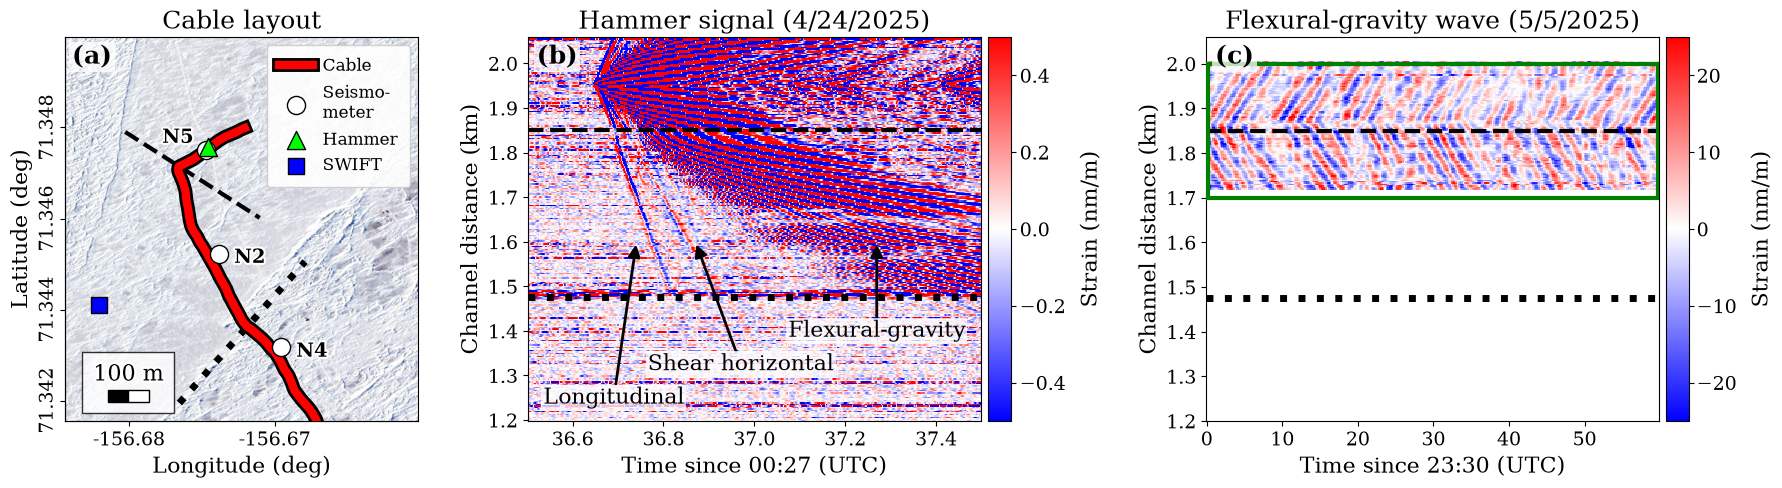

Saved: figures/combined_cable_2waterfall_3col_annotated.png
Saved: figures/combined_cable_2waterfall_3col_annotated.pdf


In [8]:
# ============================================================
# Build the combined figure with shorter panels, consistent fonts,
# and colorbars that do not overlap neighboring axes
# ============================================================

fig = plt.figure(figsize=(18, 6), constrained_layout=False)

# Seven columns:
#   map | spacer | waterfall | waterfall cbar | spacer | FK | FK cbar
#
# The panels are shorter than before, and the spacer after each colorbar
# gives enough room for the colorbar label before the next subplot starts.
gs = fig.add_gridspec(
    nrows=1,
    ncols=7,
    width_ratios=[1.0, 0.10, 1.00, 0.05, 0.4, 1.00, 0.05],
    left=0.055,
    right=0.985,
    bottom=0.20,
    top=0.84,
    wspace=0.03,
)

ax_map = fig.add_subplot(gs[0, 0])
ax_waterfall = fig.add_subplot(gs[0, 5])
cax_waterfall = fig.add_subplot(gs[0, 6])
ax_fk = fig.add_subplot(gs[0, 2])
cax_fk = fig.add_subplot(gs[0, 3])

plot_cable_layout_panel(ax_map)
_, im_waterfall = plot_waterfall_panel(ax_waterfall)
_, im_hammer = plot_hammer_panel(ax_fk)

# External colorbars with the same height as their target axes.
# Keep labels outside the bars and reduce labelpad slightly.
cb_waterfall = fig.colorbar(im_waterfall, cax=cax_waterfall)
cb_waterfall.set_label("Strain (nm/m)", fontsize=CBAR_LABEL_FONTSIZE, labelpad=10)
# cb_waterfall.set_ticks(np.arange(-1.0,1.1,0.5))
cb_waterfall.ax.tick_params(labelsize=CBAR_TICK_FONTSIZE, pad=2)

cb_hammer = fig.colorbar(im_hammer, cax=cax_fk)
cb_hammer.set_label("Strain (nm/m)", fontsize=CBAR_LABEL_FONTSIZE, labelpad=10)
cb_hammer.ax.tick_params(labelsize=CBAR_TICK_FONTSIZE, pad=3)

# Panel labels
for label, ax in zip(["(a)", "(b)", "(c)"], [ax_map, ax_fk, ax_waterfall]):
    ax.text(
        0.02,
        0.98,
        label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=PANEL_LABEL_FONTSIZE,
        fontweight="bold",
        color="black",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=2),
        zorder=100,
    )

# Panel titles
ax_map.set_title("Cable layout", fontsize=TITLE_FONTSIZE)
ax_waterfall.set_title("Flexural-gravity wave (5/5/2025)", fontsize=TITLE_FONTSIZE)
ax_fk.set_title("Hammer signal (4/24/2025)", fontsize=TITLE_FONTSIZE)

fig.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
fig.savefig(OUT_PDF, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {OUT_PNG}")
print(f"Saved: {OUT_PDF}")
